In [1]:
import numpy as np
import pandas as pd
import pyagrum as gum
import pyagrum.lib.notebook as gnb
import pyagrum.lib.dynamicBN as gdyn

from cross_impact.model import build_network, UncertaintyFactor, CrossImpactNetwork
from cross_impact.pyagrum_import import marginals_and_joint_from_pyagrum
from cross_impact.pyagrum_export import graft_onto_pyagrum
from cross_impact.model import cross_impacts_from_joint

In [2]:
# The uncertainty factors, or dnb nodes
factortuples = [
    ("HHA", 3, ()),  # 0
    ("GER", 2, ()),  # 1
    ("OMA", 2, ()),  # 2

    ("PIS0", 5, ()), # 3
    ("PIH0", 5, (0,3,)), # 4
    ("LYS0", 4, (3,4,)), # 5
    ("LYH0", 7, (0,3,4,5,)), # 6
    ("AST0", 3, (1,2,4,6,)), # 7

    ("PISt", 5, (3,4,5,6,)), # 8
    ("PIHt", 5, (1,2,4,6,8,)), # 9
    ("LYSt", 4, (1,2,5,6,8,9,)), # 10
    ("LYHt", 7, (1,2,6,8,9,10,)), # 11
    ("ASTt", 3, (9,11,)), # 12
]
factors = [UncertaintyFactor(factor[0], factor[1], factor[2]) for factor in factortuples]

In [3]:
# marginals for each uncertainty factor
hha_mar = np.array([0.3, 0.4, 0.3])
ger_mar = np.array([0.7, 0.3])
oma_mar = np.array([0.5, 0.5])
pis_mar = np.array([0.0993, 0.388, 0.4343, 0.0784, 0])
pih_mar = np.array([0.7467, 0.042, 0.14, 0.0663, 0.005])
lys_mar = np.array([0.9637, 0.0099, 0.0185, 0.0079])
lyh_mar = np.array([0.950, 0.031, 0.005, 0.01, 0.001, 0.003, 0])
ast_mar = np.array([0.5, 0.2, 0.3])

In [10]:
cross_impacts = {}
for fi, factor in enumerate(factortuples):
    for parent_index in factor[2]:
        factor_dim = factor[1]
        parent_dim = factortuples[parent_index][1]
        cross_impacts[(parent_index, fi)] = np.zeros((parent_dim, factor_dim))

for ci in cross_impacts:
    print(f"{ci}: ----- \n {cross_impacts[ci]} \n")

[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]
[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]
[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]
[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]
[[0. 0. 0.]
 [0. 0. 0.]]
[[0. 0. 0.]
 [0. 0. 0.]]
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
[[0

In [5]:
network = CrossImpactNetwork(
    factors=factors,
    marginals=[
        hha_mar,
        ger_mar,
        oma_mar,
        
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
        
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
    ],
    cross_impacts=cross_impacts,
)
built = build_network(network, mode="independent", initial_joint=None)

(CVXPY) Oct 16 04:53:33 PM: Your problem has 3 variables, 4 constraints, and 0 parameters.
(CVXPY) Oct 16 04:53:33 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 16 04:53:33 PM: DCP verification time: 0.0003 seconds.
(CVXPY) Oct 16 04:53:33 PM: Expression tree has 2 nodes.
(CVXPY) Oct 16 04:53:33 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 16 04:53:33 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 16 04:53:33 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 16 04:53:33 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Oct 16 04:53:33 PM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> EliminateZeroSized -> ConeMatrixStuffing -> CLARABEL
(CVXPY) Oct 16 04:53:33 PM: Applying reduction Dcp2Cone
(CVXPY) Oct 16 04:53:33 PM: Applying reduction CvxAttr2Constr
(CVXPY) Oct 16 04:53:33 PM: App

                                     CVXPY                                     
                                     v1.9.2                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------
-------------------------------------------------------------
           Clarabel.rs v0.11.1  -  Clever Acronym                

                   (c) Paul Goulart                          
                University of Oxford, 2022                   
-------------------------------------------------------------

problem:
  variables     = 3
  constraints  

(CVXPY) Oct 16 04:53:33 PM: Problem status: optimal
(CVXPY) Oct 16 04:53:33 PM: Optimal value: 0.000e+00
(CVXPY) Oct 16 04:53:33 PM: Compilation took 2.796e-02 seconds
(CVXPY) Oct 16 04:53:33 PM: Solver (including time spent in interface) took 3.571e-03 seconds
(CVXPY) Oct 16 04:53:33 PM: Your problem has 2 variables, 3 constraints, and 0 parameters.
(CVXPY) Oct 16 04:53:33 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 16 04:53:33 PM: DCP verification time: 0.0002 seconds.
(CVXPY) Oct 16 04:53:33 PM: Expression tree has 2 nodes.
(CVXPY) Oct 16 04:53:33 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 16 04:53:33 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 16 04:53:33 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 16 04:53:33 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Oct 16 

  0  +0.0000e+00  -0.0000e+00  0.00e+00  3.59e-01  7.48e-01  1.00e+00  1.02e+00   ------   
  1  +0.0000e+00  -1.2222e-01  1.22e-01  6.71e-02  2.13e-01  6.18e-03  2.13e-01  8.24e-01  
  2  +0.0000e+00  -9.7315e-04  9.73e-04  1.08e-03  3.35e-03  9.64e-04  4.06e-03  9.90e-01  
  3  +0.0000e+00  -9.6991e-06  9.70e-06  1.08e-05  3.35e-05  9.62e-06  4.06e-05  9.90e-01  
  4  +0.0000e+00  -9.6988e-08  9.70e-08  1.08e-07  3.35e-07  9.62e-08  4.06e-07  9.90e-01  
  5  +0.0000e+00  -9.6988e-10  9.70e-10  1.08e-09  3.35e-09  9.62e-10  4.06e-09  9.90e-01  
---------------------------------------------------------------------------------------------
Terminated with status = Solved
solve time = 258.901µs
-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------
                                     CVXPY                 

(CVXPY) Oct 16 04:53:33 PM: Problem status: optimal
(CVXPY) Oct 16 04:53:33 PM: Optimal value: 0.000e+00
(CVXPY) Oct 16 04:53:33 PM: Compilation took 1.675e-02 seconds
(CVXPY) Oct 16 04:53:33 PM: Solver (including time spent in interface) took 3.900e-03 seconds
(CVXPY) Oct 16 04:53:33 PM: Your problem has 2 variables, 3 constraints, and 0 parameters.
(CVXPY) Oct 16 04:53:33 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 16 04:53:33 PM: DCP verification time: 0.0001 seconds.
(CVXPY) Oct 16 04:53:33 PM: Expression tree has 2 nodes.
(CVXPY) Oct 16 04:53:33 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 16 04:53:33 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 16 04:53:33 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 16 04:53:33 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Oct 16 

  0  +0.0000e+00  -0.0000e+00  0.00e+00  2.84e-01  6.50e-01  1.00e+00  1.13e+00   ------   
  1  +0.0000e+00  -8.8477e-02  8.85e-02  3.61e-02  1.19e-01  6.78e-03  1.59e-01  8.79e-01  
  2  +0.0000e+00  -7.0454e-04  7.05e-04  3.94e-04  1.42e-03  3.00e-04  1.93e-03  9.90e-01  
  3  +0.0000e+00  -7.0353e-06  7.04e-06  3.94e-06  1.42e-05  3.00e-06  1.93e-05  9.90e-01  
  4  +0.0000e+00  -7.0352e-08  7.04e-08  3.94e-08  1.42e-07  3.00e-08  1.93e-07  9.90e-01  
  5  +0.0000e+00  -7.0352e-10  7.04e-10  3.94e-10  1.42e-09  3.00e-10  1.93e-09  9.90e-01  
---------------------------------------------------------------------------------------------
Terminated with status = Solved
solve time = 190.947µs
-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------
                                     CVXPY                 

... (16 outputs left out)

(CVXPY) Oct 16 04:53:41 PM: Problem status: optimal
(CVXPY) Oct 16 04:53:41 PM: Optimal value: 3.550e+00
(CVXPY) Oct 16 04:53:41 PM: Compilation took 5.369e-02 seconds
(CVXPY) Oct 16 04:53:41 PM: Solver (including time spent in interface) took 4.553e+00 seconds
(CVXPY) Oct 16 04:53:41 PM: Your problem has 19600 variables, 2807 constraints, and 0 parameters.
(CVXPY) Oct 16 04:53:41 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 16 04:53:41 PM: DCP verification time: 0.0002 seconds.
(CVXPY) Oct 16 04:53:41 PM: Expression tree has 5 nodes.
(CVXPY) Oct 16 04:53:41 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 16 04:53:41 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 16 04:53:41 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 16 04:53:41 PM: Compiling problem (target solver=OSQP).
(CVXPY) Oct 


status:               solved
solution polishing:   unsuccessful
number of iterations: 6200
optimal objective:    3.5496
dual objective:       3.5497
duality gap:          -7.9742e-05
primal-dual integral: 2.8857e+05
run time:             4.55e+00s
optimal rho estimate: 1.04e-02

-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------
                                     CVXPY                                     
                                     v1.9.2                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
-------------------------------------------------------------------------------

(CVXPY) Oct 16 04:53:57 PM: Problem status: optimal_inaccurate
(CVXPY) Oct 16 04:53:57 PM: Optimal value: 3.442e+00
(CVXPY) Oct 16 04:53:57 PM: Compilation took 5.678e-02 seconds
(CVXPY) Oct 16 04:53:57 PM: Solver (including time spent in interface) took 1.619e+01 seconds
(CVXPY) Oct 16 04:53:57 PM: Your problem has 105 variables, 38 constraints, and 0 parameters.
(CVXPY) Oct 16 04:53:57 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 16 04:53:57 PM: DCP verification time: 0.0002 seconds.
(CVXPY) Oct 16 04:53:57 PM: Expression tree has 5 nodes.
(CVXPY) Oct 16 04:53:57 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 16 04:53:57 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 16 04:53:57 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 16 04:53:57 PM: Compiling problem (target solver=OSQP).
(CVXP

10000   3.4419e+00   9.57e-06   4.65e-06  -6.21e-04   9.57e-06   1.00e-01    1.62e+01s

status:               solved inaccurate
number of iterations: 10000
optimal objective:    3.4419
dual objective:       3.4425
duality gap:          -6.2135e-04
primal-dual integral: 2.8833e+05
run time:             1.62e+01s
optimal rho estimate: 5.40e-02

-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------
                                     CVXPY                                     
                                     v1.9.2                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
---------------

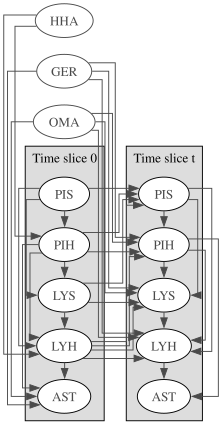

In [6]:
from cross_impact.pyagrum_export import to_pyagrum

bn = to_pyagrum(built)
gdyn.showTimeSlices(bn)

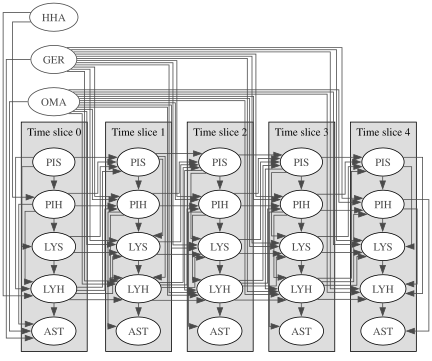

In [7]:
T = 5
dbn = gdyn.unroll2TBN(bn, T)
gdyn.showTimeSlices(dbn)

In [8]:
dbn.cpt("LYS4")

(pyagrum.Tensor@0x56534522d5a0) 
                                         ||  LYS4                                 |
GER   |OMA   |LYS3  |LYH3  |PIS4  |PIH4  ||0        |1        |2        |3        |
------|------|------|------|------|------||---------|---------|---------|---------|
0     |0     |0     |0     |0     |0     || 1.0000  | 0.0000  | 0.0000  | 0.0000  |
1     |0     |0     |0     |0     |0     || 1.0000  | 0.0000  | 0.0000  | 0.0000  |
0     |1     |0     |0     |0     |0     || 1.0000  | 0.0000  | 0.0000  | 0.0000  |
1     |1     |0     |0     |0     |0     || 1.0000  | 0.0000  | 0.0000  | 0.0000  |
0     |0     |1     |0     |0     |0     || 1.0000  | 0.0000  | 0.0000  | 0.0000  |
1     |0     |1     |0     |0     |0     || 1.0000  | 0.0000  | 0.0000  | 0.0000  |
[...2788 more line(s) ...]
0     |1     |2     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
1     |1     |2     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
0     |0     |3     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
1     |0     |3     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
0     |1     |3     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
1     |1     |3     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |